A. Draw the patterns in a 2-D diagram

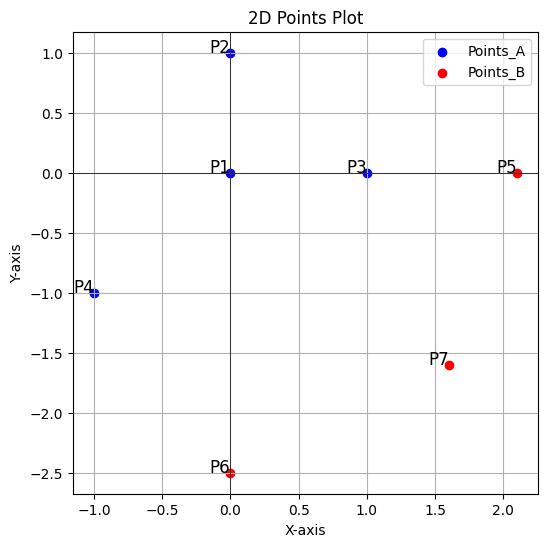

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#patterns for class A
p1 = np.array([[0],[0]])
p2 = np.array([[0],[1]])
p3 = np.array([[1],[0]])
p4 = np.array([[-1],[-1]])

#patterns for class B
p5 = np.array([[2.1],[0]])
p6 = np.array([[0],[-2.5]])
p7 = np.array([[1.6],[-1.6]])

points_A = np.array([p1,p2,p3,p4])
points_B = np.array([p5,p6,p7])

# Extract x and y coordinates
x_coords_a = points_A[:, 0]
y_coords_a = points_A[:, 1]
x_coords_b = points_B[:, 0]
y_coords_b = points_B[:, 1]

# Plot the points
plt.figure(figsize=(6, 6))
plt.scatter(x_coords_a, y_coords_a, color='blue', label='Points_A')
plt.scatter(x_coords_b, y_coords_b, color='red', label='Points_B')
plt.axhline(0, color='black', linewidth=0.5)  # x-axis
plt.axvline(0, color='black', linewidth=0.5)  # y-axis
plt.grid(True)

# Annotate the points
for i, (x, y) in enumerate(points_A):
    plt.text(x, y, f'P{i+1}', fontsize=12, ha='right')
for i, (x, y) in enumerate(points_B):
    plt.text(x, y, f'P{i+5}', fontsize=12, ha='right')

plt.title("2D Points Plot")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.legend()
plt.show()



As long as the blue points (class A) are (typically) on the left side, and the red points (class B) on the right side, we can say that the categories are linearly separable.

B. For the aforementioned patterns design the architecture of an ADALINE neural 
network which will separate the classes.

In order to implement question B, i'm going to guess the target values.
More specifically, t1=1 (class A) and t2=-1(class B). 

In [2]:
print(points_A)

[[[ 0]
  [ 0]]

 [[ 0]
  [ 1]]

 [[ 1]
  [ 0]]

 [[-1]
  [-1]]]


In [3]:
import sympy as sp

#probabilites for two classes
prob_A = 0.1
prob_B = 0.2

#guess target values
t1 = 1
t2 = -1

#i need to find F[x], c, h, R

#compute h
h1=0
h2=0
for i in range(len(points_A)):
    h1 += prob_A* t1* points_A[i]

for i in range(len(points_B)):
    h2 += prob_B * t2 * points_B[i]

h = h1 + h2

print(f"h = {h}")

#compute c
c = prob_A * t1 + prob_B * t2
print(f"c = {c}")

#compute R
R1=0
R2=0
for i in range(len(points_A)):
    R1 +=prob_A * points_A[i] * points_A[i].T

for i in range(len(points_B)):
    R1 +=prob_B * points_B[i] * points_B[i].T

R = R1 + R2
print(f"R = {R}")

#compute F

# Initialize weights (w1 and w2)
w1, w2 = sp.symbols('w1 w2')
w = sp.Matrix([w1, w2])  # Replace w1 and w2 with specific values

# Compute F(x)
F = c - 2 * (w.T * h)[0] + (w.T * R *w)[0]  # Equivalent to w^T * R * w
print("F(x):", F)

#compute x*
x_star = np.linalg.inv(R) @ h
print(f"x* = {x_star}")



h = [[-0.74]
 [ 0.82]]
c = -0.1
R = [[ 1.594 -0.412]
 [-0.412  1.962]]
F(x): w1*(1.594*w1 - 0.412*w2) + 1.48*w1 + w2*(-0.412*w1 + 1.962*w2) - 1.64*w2 - 0.1
x* = [[-0.37665958]
 [ 0.33884621]]


As long as we have found x*, we will use these two values for w1 and w2. Then, we will find a (a=w.T * p) and compute the errors e=t-a. By finding these errors, we can understand if the classes are well separated.

In [40]:
import numpy as np

x_star = x_star.flatten()
w = np.zeros_like(x_star)   #create an array for w1 and w2


#compute w1 and w2 via x*
for i in range(len(x_star)):
    w[i] = x_star[i]
    print(f"w[{i+1}] = {w[i]}")

#compute output a in order to compute error
#a1 stands for the patterns of class1 and a2 stands for the patterns of class2

#class A
w_init = np.array([w[0], w[1]])
print(w)
a1 = np.zeros(len(points_A))
e1 = np.zeros(len(points_A))

print("-------------------------------")

for i in range(len(points_A)):
    a1[i] = np.dot(w_init, points_A[i].flatten())  # Dot product
    e1[i] = t1 - a1[i]

    print(f"a1[{i+1}] = {a1[i]}")
    print(f"e1[{i+1}] = {e1[i]}")
    print("-------------------------------")

#class B
a2 = np.zeros(len(points_B))
e2 = np.zeros(len(points_B))

print("-------------------------------")

i=0
for i in range(len(points_B)):
    a2[i] = np.dot(w_init, points_B[i].flatten())  # Dot product
    e2[i] = t2 - a2[i]

    print(f"a2[{i+1}] = {a2[i]}")
    print(f"e2[{i+1}] = {e2[i]}")
    print("-------------------------------")




w[1] = -0.37665957553274776
w[2] = 0.33884620534174714
[-0.37665958  0.33884621]
-------------------------------
a1[1] = 0.0
e1[1] = 1.0
-------------------------------
a1[2] = 0.33884620534174714
e1[2] = 0.6611537946582529
-------------------------------
a1[3] = -0.37665957553274776
e1[3] = 1.3766595755327478
-------------------------------
a1[4] = 0.03781337019100062
e1[4] = 0.9621866298089994
-------------------------------
-------------------------------
a2[1] = -0.7909851086187704
e2[1] = -0.20901489138122964
-------------------------------
a2[2] = -0.8471155133543679
e2[2] = -0.15288448664563214
-------------------------------
a2[3] = -1.144809249399192
e2[3] = 0.14480924939919193
-------------------------------


The closer the value of error "e" is to 0, the better the classes are separeted well. Large "e" values indicate poor separation for that point


Conclusions for each class:
- Errors for class A (e1) are larger than zero. This means that class A for t1=1 is not well separated. We can change the value of t1 in the beggining of the code, check the errors again and see if the values of e1 are closer to 0.
-  The errors for class B are smaller and closer to 0 , indicating a better fit for this class.

C. Starting with initial weights/biases equal to a random number in [-0.5, …, 0.5] 
calculate the final (after convergence) weights/biases of the ADALINE using the 
LMS training algorithm with learning rate=0.001. 

In [5]:
import numpy as np

alpha = 0.001   #learning rate
init_w = np.random.uniform(-0.5,0.5, (1,2))  #initial weights
init_b = np.random.uniform(-0.5,0.5)         #initial bias

print(init_w)
print(init_b)

[[-0.28189291  0.35125034]]
0.20605674458003675


In [60]:
#class A
w_A = np.zeros((len(points_A)+1, 2))
b_A = np.zeros((len(points_A))+1)


#initialize w(0), b(0)
w_A[0] = init_w
print(w_A[0])
b_A[0] = init_b
print(b_A[0])
#a1[0]  = np.dot(w_A[0], points_A[0].flatten())
#e1[0] = t1 - a1[0]



for i in range(1, len(points_A)+1):
    w_A[i] = w_A[i-1] + 2* alpha * e1[i-1] * points_A[i-1].T
    b_A[i] = b_A[i-1] + 2 * alpha * e1[i-1]
    a1[i-1] = np.dot(w_A[i-1], points_A[i-1].flatten())  # Dot product
    e1[i-1] = t1 - a1[i-1]
    print(f"present pattern p{i} = {points_A[i-1]}")
    print(f"w[{i}] = {w_A[i]}")
    print(f"b[{i}] = {b_A[i]}")
    print(f"a1[{i-1}] = {a1[i-1]}")
    print(f"e1[{i-1}] = {e1[i-1]}")
    
    print("-------------------------------")
    
print("End for class A")
print("-------------------------------")

    

#class B
w_B = np.zeros((len(points_B)+1, 2))
b_B = np.zeros((len(points_B))+1)


#initialize w for class B
w_B[0] = w_A[i]
b_B[0] = b_A[i]

j=i
k=1
for k in range(1, len(points_B)+1):
    w_B[k] = w_B[k-1] + 2* alpha * e2[k-1] * points_B[k-1].T
    b_B[k] = b_B[k-1] + 2 * alpha * e2[k-1]
    a2[k-1] = np.dot(w_B[k-1], points_B[k-1].flatten())  # Dot product
    e2[k-1] = t2 - a2[k-1]
    print(f"present pattern p{j+1} = {points_B[k-1]}")
    print(f"w[{j+1}] = {w_B[k]}")
    print(f"b[{j+1}] = {b_B[k]}")
    print(f"a2[{j}] = {a2[k-1]}")
    print(f"e2[{j}] = {e2[k-1]}")
    j+=1
    
    print("-------------------------------")
   

[-0.28189291  0.35125034]
0.20605674458003675
present pattern p1 = [[0]
 [0]]
w[1] = [-0.28189291  0.35125034]
b[1] = 0.20805674458003676
a1[0] = 0.0
e1[0] = 1.0
-------------------------------
present pattern p2 = [[0]
 [1]]
w[2] = [-0.28189291  0.35254784]
b[2] = 0.20935424390762503
a1[1] = 0.35125033620586676
e1[1] = 0.6487496637941332
-------------------------------
present pattern p3 = [[1]
 [0]]
w[3] = [-0.27932913  0.35254784]
b[3] = 0.21191802973306992
a1[2] = -0.2818929127224462
e1[2] = 1.281892912722446
-------------------------------
present pattern p4 = [[-1]
 [-1]]
w[4] = [-0.28147556  0.3504014 ]
b[4] = 0.21406446715034283
a1[3] = -0.07321870863645374
e1[3] = 1.0732187086364537
-------------------------------
End for class A
-------------------------------
present pattern p5 = [[2.1]
 [0. ]]
w[5] = [-0.28319295  0.3504014 ]
b[5] = 0.2132466645204628
a2[4] = -0.5910986850599758
e2[4] = -0.40890131494002424
-------------------------------
present pattern p6 = [[ 0. ]
 [-2.5